In [1]:
import os
import cv2
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [2]:
file_list = os.listdir("original")

Xs = []
ys = []

class_id = 0
class_dict = {}

for file in file_list:
    file_name = file.replace(".gif", "")
    class_name = file_name.split("-")[0]
    image = np.asarray(Image.open(f"original/{file}").convert("L"))

    if image is None:
        print(f"Error loading image: {file}")
        continue

    if class_name not in class_dict:
        class_dict[class_name] = class_id
        class_id += 1
    
    Xs.append(image)
    ys.append(class_dict[class_name])

In [3]:
def class_id_to_name(class_id):
    for name, id in class_dict.items():
        if id == class_id:
            return name
    return None

In [4]:
train_x, test_x, train_y, test_y = train_test_split(Xs, ys, test_size=0.3, random_state=42, shuffle=True, stratify=ys)

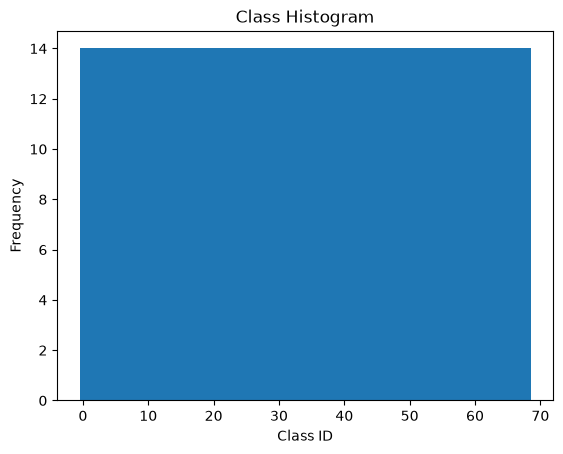

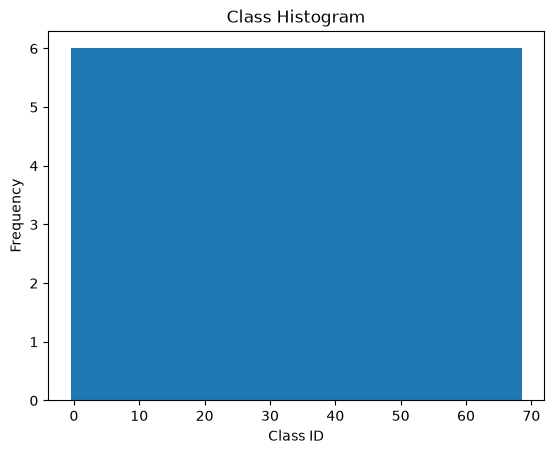

In [5]:
# plot class histogram
plt.hist(train_y, bins=len(class_dict), align='left')
plt.xlabel('Class ID')
plt.ylabel('Frequency')
plt.title('Class Histogram')
plt.show()

plt.hist(test_y, bins=len(class_dict), align='left')
plt.xlabel('Class ID')
plt.ylabel('Frequency')
plt.title('Class Histogram')
plt.show()

In [6]:
def image_features(image):
    _, thresh = cv2.threshold(image, 127, 255, cv2.THRESH_BINARY)

    contours, _ = cv2.findContours(
        thresh,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        return [0.0] * 8

    contour = max(contours, key=cv2.contourArea)

    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)

    x, y, w, h = cv2.boundingRect(contour)
    bounding_rect_area = w * h

    aspect_ratio = w / h if h > 0 else 0.0
    extent = area / bounding_rect_area if bounding_rect_area > 0 else 0.0

    hull = cv2.convexHull(contour)
    hull_area = cv2.contourArea(hull)
    solidity = area / hull_area if hull_area > 0 else 0.0

    circularity = (
        4 * np.pi * area / perimeter**2
        if perimeter > 0 else 0.0
    )

    moments = cv2.moments(contour)
    if moments["m00"] != 0:
        centroid_x = moments["m10"] / moments["m00"]
        centroid_y = moments["m01"] / moments["m00"]
    else:
        centroid_x = centroid_y = 0.0

    return [
        area,
        perimeter,
        bounding_rect_area,
        aspect_ratio,
        extent,
        solidity,
        circularity,
        centroid_x,
        centroid_y,
    ]

In [7]:
def center_and_normalize(binary, output_size=512, margin=5):
    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        return np.zeros(
            (output_size, output_size),
            dtype=np.uint8
        )

    contour = max(contours, key=cv2.contourArea)

    moments = cv2.moments(contour)

    if moments["m00"] == 0:
        return np.zeros(
            (output_size, output_size),
            dtype=np.uint8
        )

    cx = moments["m10"] / moments["m00"]
    cy = moments["m01"] / moments["m00"]

    x, y, w, h = cv2.boundingRect(contour)

    object_radius = max(
        cx - x,
        x + w - cx,
        cy - y,
        y + h - cy
    )

    available_radius = output_size / 2 - margin

    scale = (
        available_radius / object_radius
        if object_radius > 0 else 1.0
    )

    target_center = output_size / 2

    transformation = np.array([
        [scale, 0, target_center - scale * cx],
        [0, scale, target_center - scale * cy]
    ], dtype=np.float32)

    normalized = cv2.warpAffine(
        binary,
        transformation,
        (output_size, output_size),
        flags=cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    return normalized

Class ID: truck


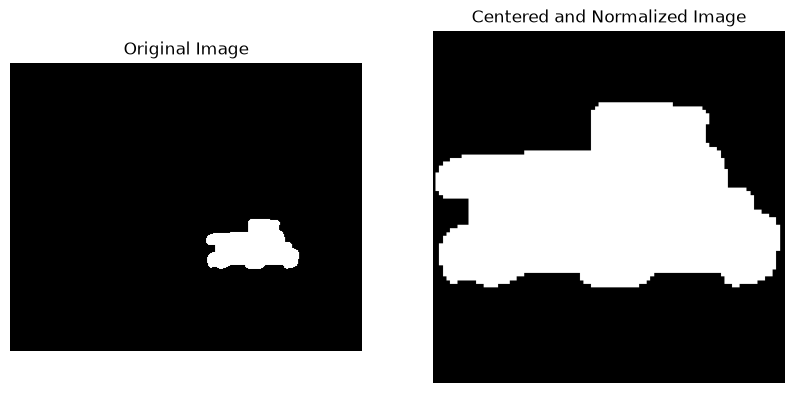

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
idx = 45

axes[0].imshow(train_x[idx], cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(center_and_normalize(train_x[idx]), cmap='gray')
axes[1].set_title('Centered and Normalized Image')
axes[1].axis('off')

print(f"Class ID: {class_id_to_name(train_y[idx])}")

In [9]:
X_train_processed = [image_features(center_and_normalize(image)) for image in train_x]
X_test_processed = [image_features(center_and_normalize(image)) for image in test_x]

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_processed)
X_test_scaled = scaler.transform(X_test_processed)

In [11]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier()
clf.fit(X_train_processed, train_y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [12]:
from sklearn.metrics import f1_score, accuracy_score, classification_report

y_pred = clf.predict(X_test_processed)

print("Accuracy:", accuracy_score(test_y, y_pred))
print("F1 Score:", f1_score(test_y, y_pred, average='weighted'))
print("Classification Report:\n", classification_report(test_y, y_pred))

Accuracy: 0.7690476190476191
F1 Score: 0.761519512233798
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.83      0.83         6
           1       1.00      1.00      1.00         6
           2       1.00      1.00      1.00         6
           3       1.00      0.83      0.91         6
           4       0.43      0.50      0.46         6
           5       0.75      1.00      0.86         6
           6       0.75      1.00      0.86         6
           7       0.29      0.33      0.31         6
           8       0.71      0.83      0.77         6
           9       1.00      0.67      0.80         6
          10       0.40      0.33      0.36         6
          11       0.86      1.00      0.92         6
          12       1.00      0.67      0.80         6
          13       0.50      0.67      0.57         6
          14       0.67      0.67      0.67         6
          15       0.75      1.00      0.86         6


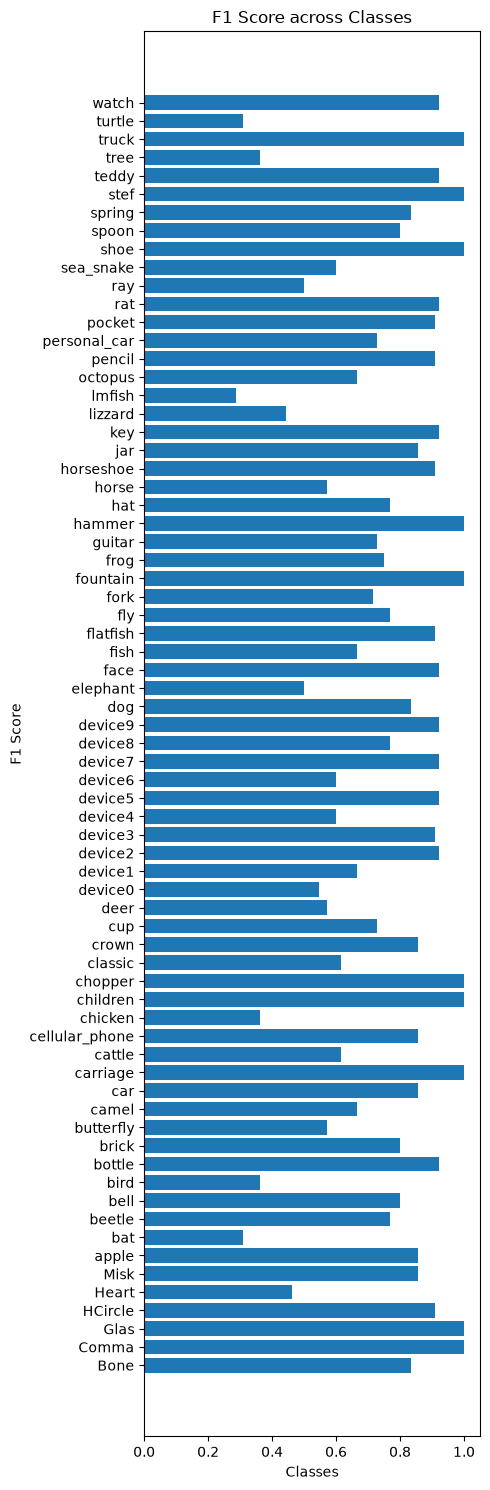

In [13]:
import matplotlib.pyplot as plt

f1_scores = f1_score(test_y, y_pred, average=None, labels=clf.classes_)

plt.figure(figsize=(5, 15))
plt.barh(list(class_dict.keys()), f1_scores)
plt.xlabel('Classes')
plt.ylabel('F1 Score')
plt.title('F1 Score across Classes')
plt.tight_layout()
plt.show()

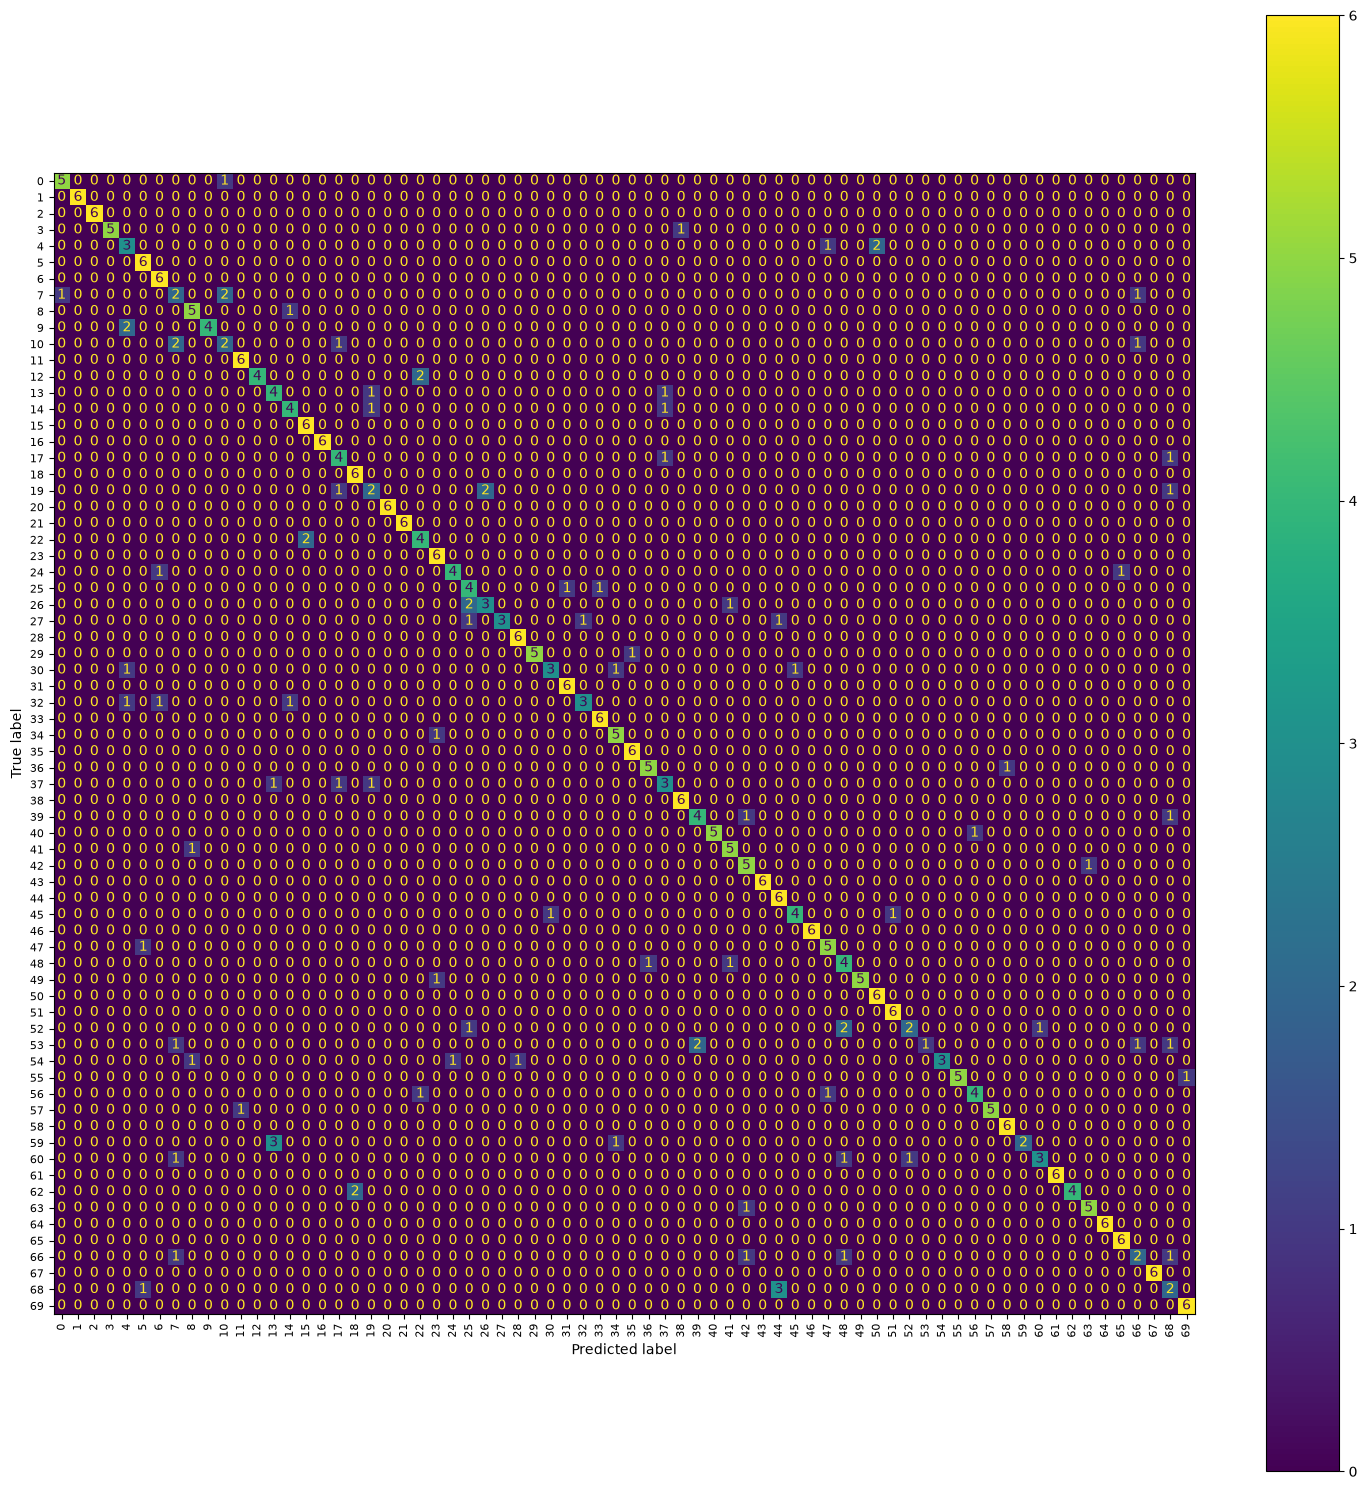

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

matrix = confusion_matrix(test_y, y_pred, labels=clf.classes_)
fig = plt.figure(figsize=(15, 15))
ax = fig.gca()

ConfusionMatrixDisplay(confusion_matrix=matrix).plot(ax=ax)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=90,           # użyj 45 dla etykiet pod kątem
    ha="center",
    fontsize=8
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    fontsize=8
)

fig.tight_layout()

plt.show()

In [24]:

def fft_features(image, k: int = 20):
    image = cv2.resize(image, (256, 256))

    _, binary = cv2.threshold(
        image, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    F = np.fft.fftshift(np.fft.fft2(binary.astype(float)))

    magnitude = np.abs(F)

    h, w = magnitude.shape
    cy, cx = h // 2, w // 2

    magnitude[cy, cx] = 0

    scale = np.linalg.norm(magnitude)
    if scale > 0:
        magnitude /= scale

    y, x = np.indices((h, w))
    fy = y - cy
    fx = x - cx

    mask = (fy > 0) | ((fy == 0) & (fx > 0))

    distances = fx[mask]**2 + fy[mask]**2
    indices = np.argsort(distances, kind="stable")

    descriptors = magnitude[mask][indices[:2*k]]

    return descriptors


In [25]:
X_train_fft1d = [fft_features(image) for image in train_x]
X_test_fft1d = [fft_features(image) for image in test_x]

In [26]:
scaler_fft1d = StandardScaler()
X_train_fft1d_scaled = scaler_fft1d.fit_transform(X_train_fft1d)
X_test_fft1d_scaled = scaler_fft1d.transform(X_test_fft1d)

In [27]:
clf_fft1d = RandomForestClassifier()
clf_fft1d.fit(X_train_fft1d_scaled, train_y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [28]:
y_pred = clf_fft1d.predict(X_test_fft1d_scaled)

print("Accuracy:", accuracy_score(test_y, y_pred))
print("F1 Score:", f1_score(test_y, y_pred, average='weighted'))
print("Classification Report:\n", classification_report(test_y, y_pred))

Accuracy: 0.7714285714285715
F1 Score: 0.7583416395634442
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.67      0.80         6
           1       0.75      1.00      0.86         6
           2       0.86      1.00      0.92         6
           3       1.00      0.83      0.91         6
           4       0.71      0.83      0.77         6
           5       0.67      1.00      0.80         6
           6       0.86      1.00      0.92         6
           7       0.75      1.00      0.86         6
           8       0.31      0.67      0.42         6
           9       1.00      0.67      0.80         6
          10       0.67      0.33      0.44         6
          11       1.00      1.00      1.00         6
          12       1.00      1.00      1.00         6
          13       0.50      0.50      0.50         6
          14       1.00      0.67      0.80         6
          15       0.75      1.00      0.86         6

In [31]:
scores = {}

for preprocessing in ["with", "without"]:

    x_train_images = train_x.copy()
    x_test_images = test_x.copy()

    if preprocessing == "with":
        x_train_images = [center_and_normalize(image) for image in x_train_images]
        x_test_images = [center_and_normalize(image) for image in x_test_images]

    for features in ["simple", "fft", "both_concat"]:
        if features == "simple":
            x_train_images_ftrs = [image_features(image) for image in x_train_images]
            x_test_images_ftrs = [image_features(image) for image in x_test_images]
        elif features == "fft":
            x_train_images_ftrs = [fft_features(image) for image in x_train_images]
            x_test_images_ftrs = [fft_features(image) for image in x_test_images]
        elif features == "both_concat":
            x_train_images_ftrs = [np.hstack([image_features(image), fft_features(image)]) for image in x_train_images]
            x_test_images_ftrs = [np.hstack([image_features(image), fft_features(image)]) for image in x_test_images]

        bench_scaler = StandardScaler()
        x_train_images_scaled = bench_scaler.fit_transform(x_train_images_ftrs)
        x_test_images_scaled = bench_scaler.transform(x_test_images_ftrs)

        bench_clf = RandomForestClassifier()
        bench_clf.fit(x_train_images_scaled, train_y)

        y_pred = bench_clf.predict(x_test_images_scaled)

        f1 = f1_score(test_y, y_pred, average='weighted')
        acc = accuracy_score(test_y, y_pred)
        print(f"{features}_{preprocessing}_preprocessing")
        print("Accuracy:", acc)
        print("F1 Score:", f1)

        scores[f"{features}_{preprocessing}_preprocessing"] = {
            "f1": f1,
            "accuracy": acc
        }

simple_with_preprocessing
Accuracy: 0.7690476190476191
F1 Score: 0.7608497058497057
fft_with_preprocessing
Accuracy: 0.8
F1 Score: 0.7822463647463649
both_concat_with_preprocessing
Accuracy: 0.8690476190476191
F1 Score: 0.8641890649033508
simple_without_preprocessing
Accuracy: 0.8571428571428571
F1 Score: 0.8538662131519273
fft_without_preprocessing
Accuracy: 0.7761904761904762
F1 Score: 0.7665732983169958
both_concat_without_preprocessing
Accuracy: 0.9095238095238095
F1 Score: 0.9074568288854004


In [33]:
import pandas as pd

df = pd.DataFrame([
    {
        "Features": key.rsplit("_", 2)[0],
        "Preprocessing": key.rsplit("_", 2)[1],
        "Accuracy": values["accuracy"],
        "F1 Score": values["f1"]
    }
    for key, values in scores.items()
])

df = df.sort_values("F1 Score", ascending=False).reset_index(drop=True)

(
df.style
    .format({"Accuracy": "{:.4f}", "F1 Score": "{:.4f}"})
    .background_gradient(subset=["Accuracy", "F1 Score"], cmap="YlGn")
)

,Features,Preprocessing,Accuracy,F1 Score
0,both_concat,without,0.9095,0.9075
1,both_concat,with,0.8690,0.8642
2,simple,without,0.8571,0.8539
3,fft,with,0.8000,0.7822
4,fft,without,0.7762,0.7666
5,simple,with,0.7690,0.7608
